# Subscription Renewal Prediction using Logistic Regression


### Step 1 - Import Libraries


In [89]:
# Import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import ML tools from sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    confusion_matrix, 
    classification_report,
    roc_curve,
    auc
)

### Step 2 - Load Dataset


In [90]:
# Load the dataset
df = pd.read_csv('subscription_renewal.csv')

# Show the first 5 rows of the data
df.head()

,Customer_ID,Age,Gender,Tenure,Monthly_Charges,Support_Calls,Renewal
0,1001,56,Female,19,82.51,4,1
1,1002,69,Male,17,88.91,4,1
2,1003,46,Male,5,110.62,0,1
3,1004,32,Female,4,80.60,0,1
4,1005,60,Male,10,50.27,7,0


In [91]:
# Check the shape of the dataset
print("Dataset Shape:", df.shape)

Dataset Shape: (500, 7)


In [92]:
# Display column names
print("Columns in the dataset:")
print(df.columns)

Columns in the dataset:
Index(['Customer_ID', 'Age', 'Gender', 'Tenure', 'Monthly_Charges',
       'Support_Calls', 'Renewal'],
      dtype='object')


In [93]:
# Show structural information of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer_ID      500 non-null    int64  
 1   Age              500 non-null    int64  
 2   Gender           500 non-null    object 
 3   Tenure           500 non-null    int64  
 4   Monthly_Charges  500 non-null    float64
 5   Support_Calls    500 non-null    int64  
 6   Renewal          500 non-null    int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 27.5+ KB


In [94]:
# Statistical summary of numerical columns
df.describe()

,Customer_ID,Age,Tenure,Monthly_Charges,Support_Calls,Renewal
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,1250.500000,44.220000,12.444000,68.449560,3.916000,0.504000
std,144.481833,15.036082,7.121538,30.424144,2.560871,0.500485
min,1001.000000,18.000000,1.000000,15.020000,0.000000,0.000000
25%,1125.750000,32.000000,6.000000,42.597500,2.000000,0.000000
50%,1250.500000,45.000000,12.500000,69.675000,4.000000,1.000000
75%,1375.250000,57.000000,19.000000,94.217500,6.000000,1.000000
max,1500.000000,69.000000,24.000000,119.930000,8.000000,1.000000


### Step 3 - Exploratory Data Analysis


In [95]:
# Check for missing values
df.isnull().sum()

Customer_ID        0
Age                0
Gender             0
Tenure             0
Monthly_Charges    0
Support_Calls      0
Renewal            0
dtype: int64

In [96]:
# Check class distribution
print(df['Renewal'].value_counts())

Renewal
1    252
0    248
Name: count, dtype: int64


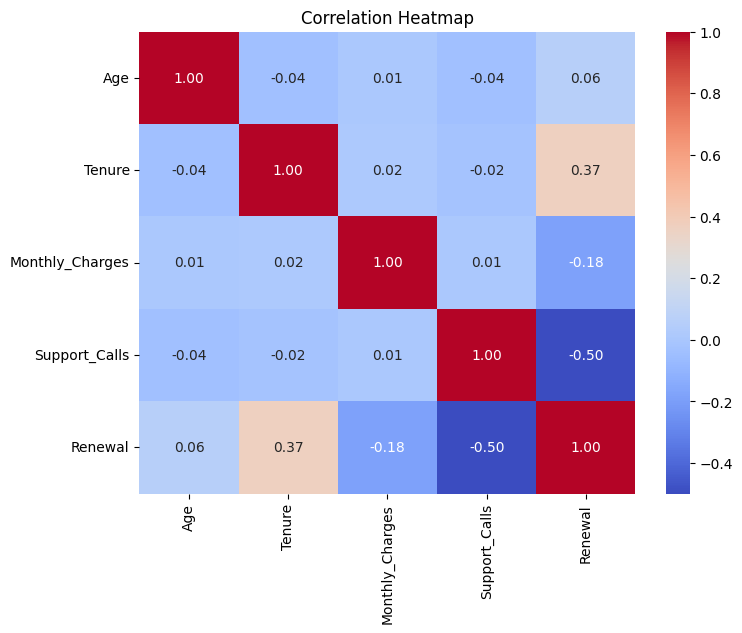

In [97]:
# Select only numeric columns for correlation
numeric_cols = df.select_dtypes(include=[np.number]).drop(columns=['Customer_ID'])
corr_matrix = numeric_cols.corr()

# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

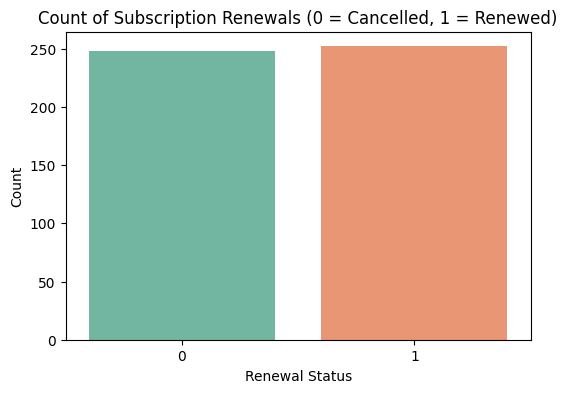

In [98]:
# Count plot of subscription renewal
plt.figure(figsize=(6, 4))
sns.countplot(x='Renewal', data=df, hue='Renewal', palette='Set2', legend=False)
plt.title('Count of Subscription Renewals (0 = Cancelled, 1 = Renewed)')
plt.xlabel('Renewal Status')
plt.ylabel('Count')
plt.show()

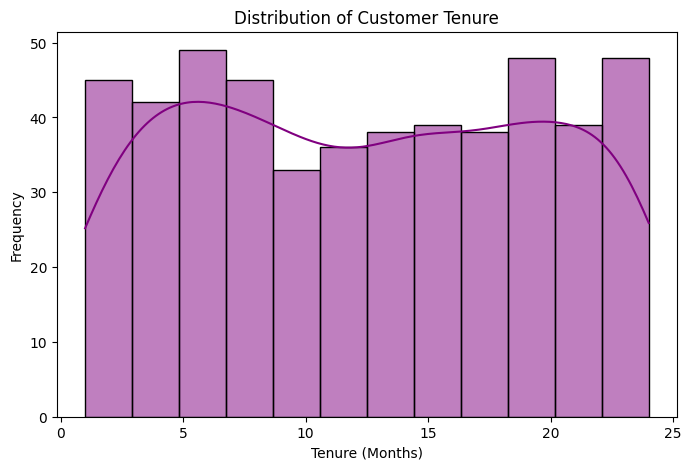

In [99]:
# Histogram of customer tenure in months
plt.figure(figsize=(8, 5))
sns.histplot(df['Tenure'], bins=12, kde=True, color='purple')
plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (Months)')
plt.ylabel('Frequency')
plt.show()

### Step 4 - Data Preprocessing


In [100]:
# Encode categorical column (Gender)
label_encoder = LabelEncoder()
df['Gender'] = label_encoder.fit_transform(df['Gender'])
df.head()

,Customer_ID,Age,Gender,Tenure,Monthly_Charges,Support_Calls,Renewal
0,1001,56,0,19,82.51,4,1
1,1002,69,1,17,88.91,4,1
2,1003,46,1,5,110.62,0,1
3,1004,32,0,4,80.60,0,1
4,1005,60,1,10,50.27,7,0


In [101]:
# Separate features and target
X = df.drop(columns=['Customer_ID', 'Renewal'])
y = df['Renewal']
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (500, 5)
Target shape: (500,)


In [102]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (400, 5)
Test shape: (100, 5)


In [103]:
# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 5 - Model Training


In [104]:
# Initialize and train Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
print("Model training finished!")

Model training finished!


### Step 6 - Prediction


In [105]:
# Predict on test dataset
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

### Step 7 - Evaluation


In [106]:
# Print classification metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  0.8400
Precision: 0.8868
Recall:    0.8246
F1 Score:  0.8545


In [107]:
# Print confusion matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

Confusion Matrix:
[[37  6]
 [10 47]]


In [108]:
# Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.86      0.82        43
           1       0.89      0.82      0.85        57

    accuracy                           0.84       100
   macro avg       0.84      0.84      0.84       100
weighted avg       0.84      0.84      0.84       100



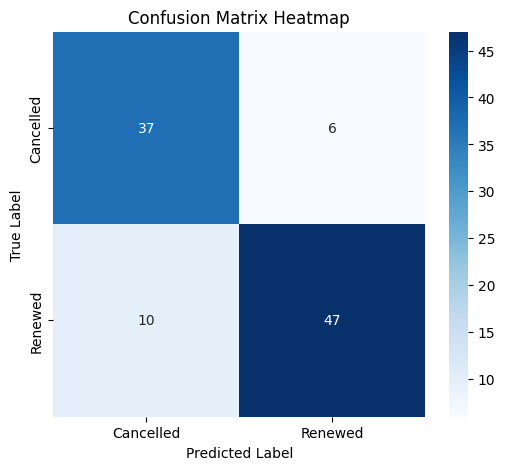

In [109]:
# Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Cancelled', 'Renewed'], yticklabels=['Cancelled', 'Renewed'])
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

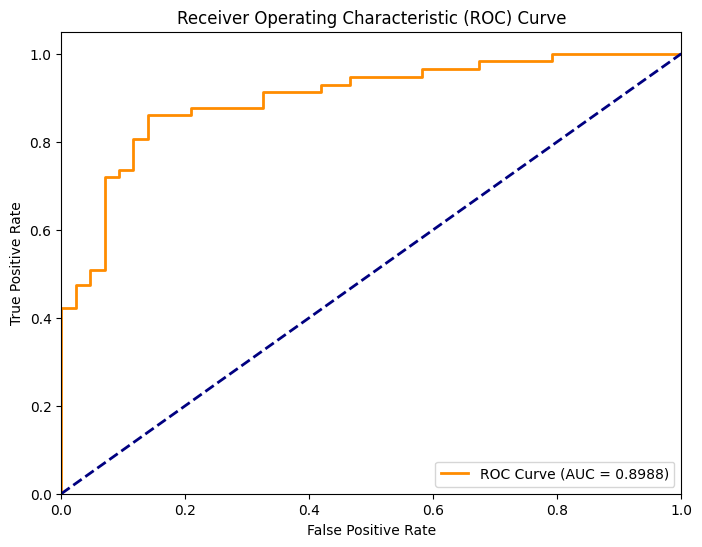

In [110]:
# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

In [111]:
import joblib

# Save the trained Logistic Regression model
joblib.dump(model, "subscription_model.pkl")

# Save the scaler
joblib.dump(scaler, "scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
